In [89]:
import sys
sys.path.append("..")

import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader
from torch import cuda

import copy
import matplotlib.pyplot as plt

from src.data_cleaning import load_data
from src.models import create_logistic_regression, create_random_forest_search, MLP
from src.evaluation import (
    evaluate_model,
    select_threshold,
    plot_confusion_matrix,
    plot_precision_recall_curve,
    compare_models,
    plot_precision_recall_comparison
)

In [90]:
RANDOM_STATE = 40

X, y = load_data()

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, random_state=RANDOM_STATE, stratify=y)

X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=RANDOM_STATE, stratify=y_temp)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

### Logistic Regression

In [91]:
model_reg = create_logistic_regression(RANDOM_STATE)

model_reg.fit(X_train, y_train)

,"l1_ratios l1_ratios: array-like of shape (n_l1_ratios), default=NoneFloats between 0 and 1 passed as Elastic-Net mixing parameter (scaling betweenL1 and L2 penalties). For `l1_ratio = 0` the penalty is an L2 penalty. For`l1_ratio = 1` it is an L1 penalty. For `0 < l1_ratio < 1`, the penalty is acombination of L1 and L2.All the values of the given array-like are tested by cross-validation and theone giving the best prediction score is used... warning:: Certain values of `l1_ratios`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... deprecated:: 1.8 `l1_ratios=None` is deprecated in 1.8 and will raise an error in version 1.10. Default value will change from `None` to `(0.0,)` in version 1.10.","(0.0,)"
,"cv cv: int or cross-validation generator, default=NoneThe default cross-validation generator used is Stratified K-Folds.If an integer is provided, it specifies the number of folds, `n_folds`, used.See the module :mod:`sklearn.model_selection` module for thelist of possible cross-validation objects... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"scoring scoring: str or callable, default=NoneThe scoring method to use for cross-validation. Options:- str: see :ref:`scoring_string_names` for options.- callable: a scorer callable object (e.g., function) with signature ``scorer(estimator, X, y)``. See :ref:`scoring_callable` for details.- `None`: :ref:`accuracy <accuracy_score>` is used... versionchanged:: 1.11 The default will change from None, i.e. accuracy, to 'neg_log_loss' in version 1.11.",'recall'
,"max_iter max_iter: int, default=100Maximum number of iterations of the optimization algorithm.",1000
,"random_state random_state: int, RandomState instance, default=NoneUsed when `solver='sag'`, 'saga' or 'liblinear' to shuffle the data.Note that this only applies to the solver and not the cross-validationgenerator. See :term:`Glossary <random_state>` for details.",40
,"use_legacy_attributes use_legacy_attributes: bool, default=TrueIf True, use legacy values for attributes:- `C_` is an ndarray of shape (n_classes,) with the same value repeated- `l1_ratio_` is an ndarray of shape (n_classes,) with the same value repeated- `coefs_paths_` is a dict with class labels as keys and ndarrays as values- `scores_` is a dict with class labels as keys and ndarrays as values- `n_iter_` is an ndarray of shape (1, n_folds, n_cs) or similarIf False, use new values for attributes:- `C_` is a float- `l1_ratio_` is a float- `coefs_paths_` is an ndarray of shape (n_folds, n_l1_ratios, n_cs, n_classes, n_features) For binary problems (n_classes=2), the 2nd last dimension is 1.- `scores_` is an ndarray of shape (n_folds, n_l1_ratios, n_cs)- `n_iter_` is an ndarray of shape (n_folds, n_l1_ratios, n_cs).. versionchanged:: 1.10 The default will change from True to False in version 1.10... deprecated:: 1.10 `use_legacy_attributes` will be deprecated in version 1.10 and be removed in 1.12.",False
,"Cs Cs: int or list of floats, default=10Each of the values in Cs describes the inverse of regularizationstrength. If Cs is as an int, then a grid of Cs values are chosenin a logarithmic scale between 1e-4 and 1e4.Like in support vector machines, smaller values specify strongerregularization.",10
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer dual=False whenn_samples > n_features.",False
,"penalty penalty: {'l1', 'l2', 'elasticnet'}, default='l2'Specify the norm of the penalty:- `'l2'`: add an L2 penalty term (used by default);- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms ar

In [92]:
y_proba_val_logreg = model_reg.predict_proba(X_val)[:, 1]

threshold_logreg, val_metrics_logreg = select_threshold(
    y_val,
    y_proba_val_logreg,
    min_precision=0.5
)

if threshold_logreg is not None:
    print(f"Selected threshold: {threshold_logreg:.4f}")
    print(f"Validation precision: {val_metrics_logreg['precision']:.4f}")
    print(f"Validation recall: {val_metrics_logreg['recall']:.4f}")
else:
    print("No threshold satisfies the precision constraint.")

Selected threshold: 0.1518
Validation precision: 0.6364
Validation recall: 1.0000


In [93]:
if threshold_logreg is not None:
    y_proba_logreg_all = model_reg.predict_proba(X_test)
    y_proba_logreg = y_proba_logreg_all[:, 1]

    y_pred_logreg = (y_proba_logreg >= threshold_logreg).astype(int)

    loss_logreg = sklearn.metrics.log_loss(
        y_test,
        y_proba_logreg_all
    )
    print(f"Test loss: {loss_logreg:.4f}")

    logreg_metrics = evaluate_model(
        y_test,
        y_pred_logreg,
        y_proba_logreg,
        loss=loss_logreg,
        threshold=threshold_logreg
    )

Test loss: 0.3155


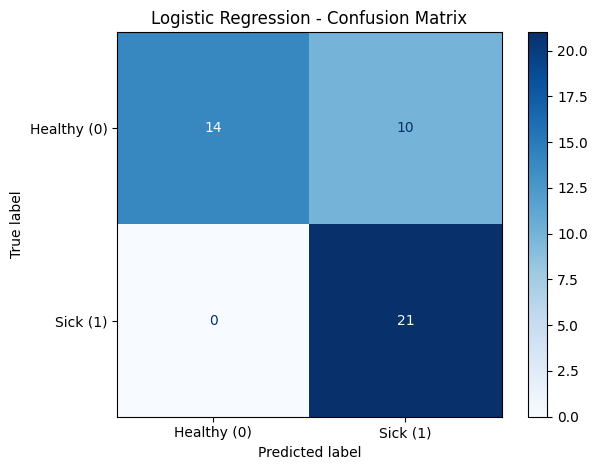

In [94]:
plot_confusion_matrix(
    y_test,
    y_pred_logreg,
    "Logistic Regression"
)

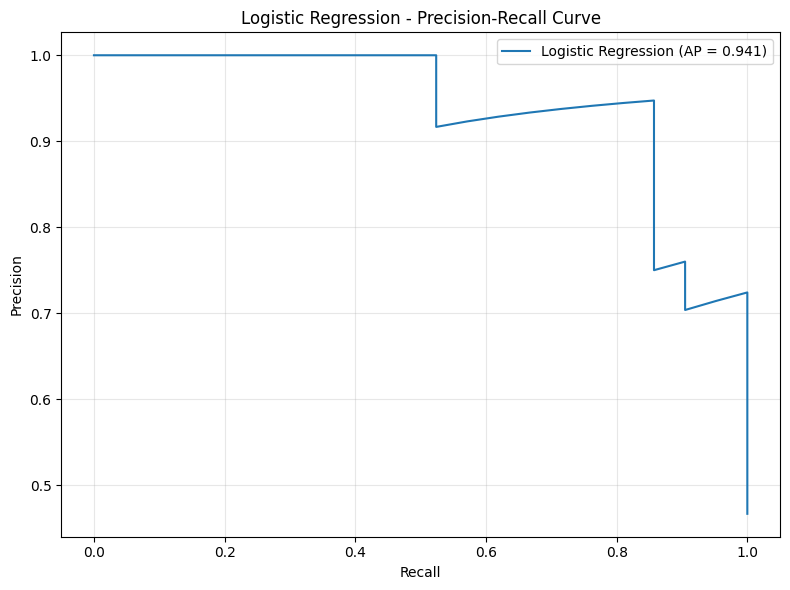

In [95]:
logreg_curve = plot_precision_recall_curve(
    y_test,
    y_proba_logreg,
    "Logistic Regression"
)

### Random Forest

In [96]:
grid = create_random_forest_search(RANDOM_STATE)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)
print("")

best_model = grid.best_estimator_

{'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 50}
0.8



In [97]:
y_proba_val_rf = best_model.predict_proba(X_val)[:, 1]

threshold_rf, val_metrics_rf = select_threshold(
    y_val,
    y_proba_val_rf,
    min_precision=0.5
)

if threshold_rf is not None:
    print(f"Selected threshold: {threshold_rf:.4f}")
    print(f"Validation precision: {val_metrics_rf['precision']:.4f}")
    print(f"Validation recall: {val_metrics_rf['recall']:.4f}")
else:
    print("No threshold satisfies the precision constraint.")

Selected threshold: 0.1400
Validation precision: 0.5833
Validation recall: 1.0000


In [98]:
if threshold_rf is not None:
    y_proba_rf_all = best_model.predict_proba(X_test)
    y_proba_rf = y_proba_rf_all[:, 1]

    y_pred_rf = (y_proba_rf >= threshold_rf).astype(int)

    loss_rf = sklearn.metrics.log_loss(y_test, y_proba_rf_all)
    print(f"Test loss: {loss_rf:.4f}")

    rf_metrics = evaluate_model(
        y_test,
        y_pred_rf,
        y_proba_rf,
        loss=loss_rf,
        threshold=threshold_rf
    )

Test loss: 0.3934


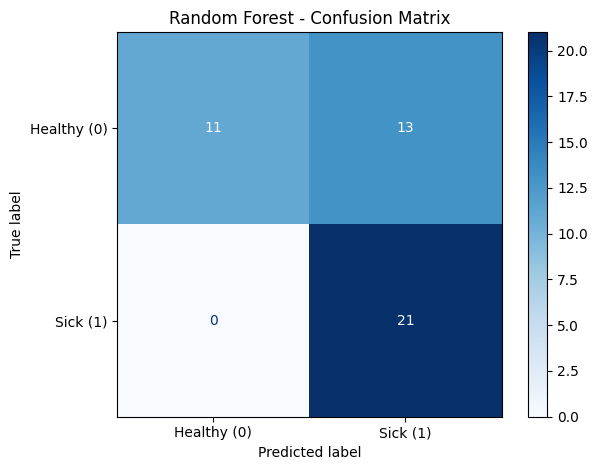

In [99]:
plot_confusion_matrix(
    y_test,
    y_pred_rf,
    "Random Forest"
)

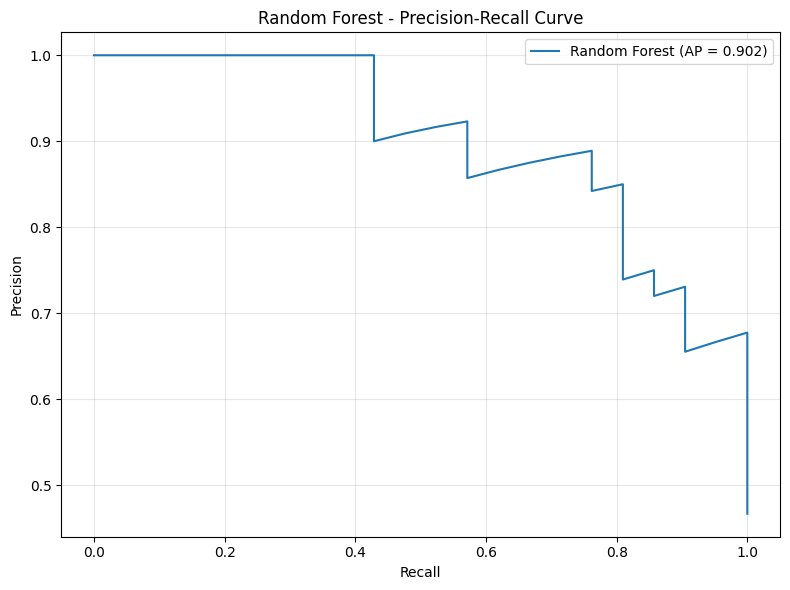

In [100]:
rf_curve = plot_precision_recall_curve(
    y_test,
    y_proba_rf,
    "Random Forest"
)

### Multi-Layer Perceptron (MLP)

In [101]:
BATCH_SIZE = 16
DROPOUT = 0.3
LEARNING_RATE = 1e-4
MOMENTUM = 0.9
WEIGHT_DECAY = 1e-3
EPOCHS = 2000


device = "cuda" if cuda.is_available() else "cpu"
print(f"Current device: {device}")

Current device: cpu


In [102]:
Xt_train = torch.tensor(X_train, dtype=torch.float32, device=device)
yt_train = torch.tensor(y_train.to_numpy(), dtype=torch.long, device=device)

Xt_val = torch.tensor(X_val, dtype=torch.float32, device=device)
yt_val = torch.tensor(y_val.to_numpy(), dtype=torch.long, device=device)

Xt_test = torch.tensor(X_test, dtype=torch.float32, device=device)
yt_test = torch.tensor(y_test.to_numpy(), dtype=torch.long, device=device)


in_features = Xt_train.shape[1]
out_features = len(torch.unique(yt_train))

train_dataset = TensorDataset(Xt_train, yt_train)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

In [103]:
mlp_model = MLP(in_features, out_features, DROPOUT).to(device)
optimizer = torch.optim.SGD(params=mlp_model.parameters(), lr=LEARNING_RATE, momentum=MOMENTUM, weight_decay=WEIGHT_DECAY)
criterion = nn.CrossEntropyLoss()

In [104]:
train_losses = []
val_losses = []

best_val_loss = float("inf")
best_weights = None
best_epoch = 0

for epoch in range(1, EPOCHS + 1):

    mlp_model.train()
    mean_train_loss = 0

    for Xt_batch, yt_batch in train_loader:

        yt_pred = mlp_model(Xt_batch)

        train_loss = criterion(yt_pred, yt_batch)
        mean_train_loss += (
            train_loss.item()
            * Xt_batch.shape[0]
            / len(train_loader.dataset)
        )

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

    mlp_model.eval()

    with torch.no_grad():
        yt_pred = mlp_model(Xt_val)
        val_loss = criterion(yt_pred, yt_val).item()

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(mlp_model.state_dict())
            best_epoch = epoch

    if epoch % 100 == 0:
        train_losses.append(mean_train_loss)
        val_losses.append(val_loss)

        print(f"Epoch: {epoch}")
        print(f"Train loss: {mean_train_loss:.4f}")
        print(f"Val loss: {val_loss:.4f}")
        print("")

mlp_model.load_state_dict(best_weights)

print("")
print(f"Best epoch: {best_epoch}")
print(f"Best validation loss: {best_val_loss:.4f}")

Epoch: 100
Train loss: 0.6411
Val loss: 0.6263

Epoch: 200
Train loss: 0.5839
Val loss: 0.5574

Epoch: 300
Train loss: 0.5263
Val loss: 0.4772

Epoch: 400
Train loss: 0.4618
Val loss: 0.4187

Epoch: 500
Train loss: 0.4541
Val loss: 0.3888

Epoch: 600
Train loss: 0.4205
Val loss: 0.3750

Epoch: 700
Train loss: 0.3764
Val loss: 0.3676

Epoch: 800
Train loss: 0.3870
Val loss: 0.3628

Epoch: 900
Train loss: 0.3918
Val loss: 0.3597

Epoch: 1000
Train loss: 0.4194
Val loss: 0.3565

Epoch: 1100
Train loss: 0.3673
Val loss: 0.3539

Epoch: 1200
Train loss: 0.3368
Val loss: 0.3511

Epoch: 1300
Train loss: 0.3730
Val loss: 0.3487

Epoch: 1400
Train loss: 0.3771
Val loss: 0.3455

Epoch: 1500
Train loss: 0.3528
Val loss: 0.3428

Epoch: 1600
Train loss: 0.3355
Val loss: 0.3403

Epoch: 1700
Train loss: 0.3599
Val loss: 0.3383

Epoch: 1800
Train loss: 0.3290
Val loss: 0.3361

Epoch: 1900
Train loss: 0.3351
Val loss: 0.3352

Epoch: 2000
Train loss: 0.3224
Val loss: 0.3342


Best epoch: 1991
Best valida

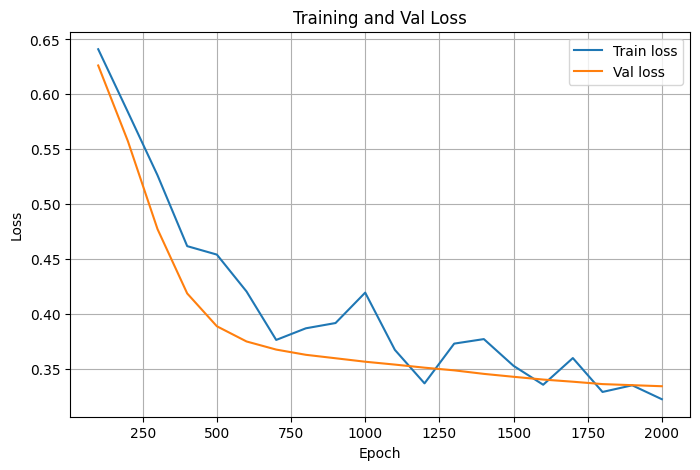

In [105]:
epochs = range(100, EPOCHS + 1, 100)

# Graphe 1 : Loss
plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, label="Train loss")
plt.plot(epochs, val_losses, label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Val Loss")
plt.legend()
plt.grid(True)
plt.show()

In [106]:
mlp_model.eval()

with torch.no_grad():
    yt_pred_val = mlp_model(Xt_val)
    y_proba_val_mlp = torch.softmax(
        yt_pred_val, dim=1
    )[:, 1].cpu().numpy()

y_true_val_mlp = yt_val.cpu().numpy()

threshold_mlp, val_metrics_mlp = select_threshold(
    y_true_val_mlp,
    y_proba_val_mlp,
    min_precision=0.5
)

if threshold_mlp is not None:
    print(f"Selected threshold: {threshold_mlp:.4f}")
    print(f"Validation precision: {val_metrics_mlp['precision']:.4f}")
    print(f"Validation recall: {val_metrics_mlp['recall']:.4f}")
else:
    print("No threshold satisfies the precision constraint.")

Selected threshold: 0.1662
Validation precision: 0.6774
Validation recall: 1.0000


In [107]:
if threshold_mlp is not None:
    mlp_model.eval()

    with torch.no_grad():
        yt_pred = mlp_model(Xt_test)
        mlp_loss = criterion(yt_pred, yt_test).item()

        y_true_mlp = yt_test.cpu().numpy()
        y_proba_mlp = torch.softmax(
            yt_pred, dim=1
        )[:, 1].cpu().numpy()

        y_pred_mlp = (
            y_proba_mlp >= threshold_mlp
        ).astype(int)

    print(f"Test loss: {mlp_loss:.4f}")

    mlp_metrics = evaluate_model(
        y_true_mlp,
        y_pred_mlp,
        y_proba_mlp,
        loss=mlp_loss,
        threshold=threshold_mlp
    )

Test loss: 0.3708


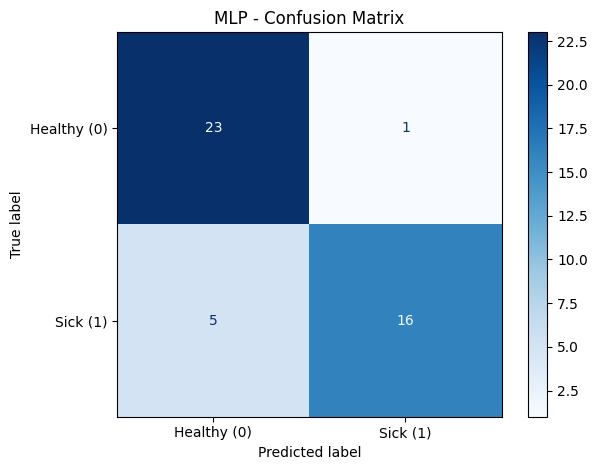

In [108]:
plot_confusion_matrix(
    yt_test.cpu().numpy(),
    yt_pred_class.cpu().numpy(),
    "MLP"
)

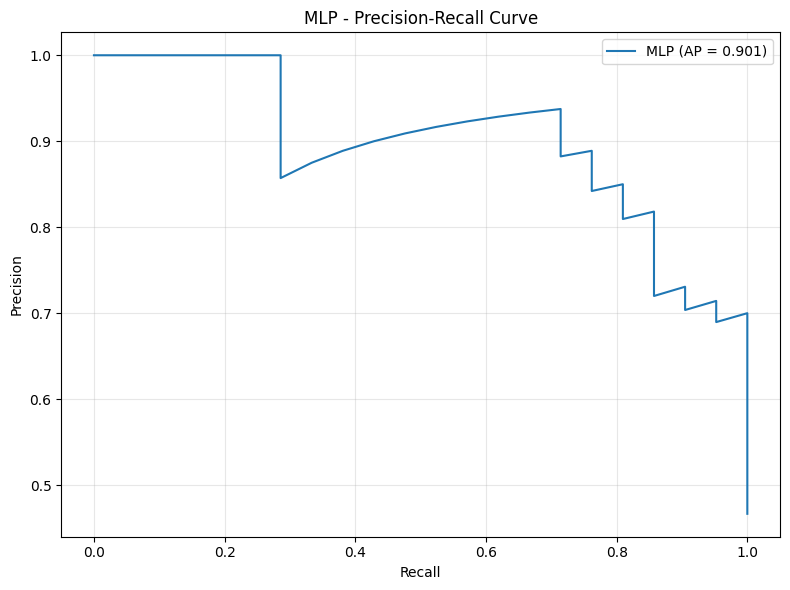

In [109]:
mlp_curve = plot_precision_recall_curve(
    y_true_mlp,
    y_proba_mlp,
    "MLP"
)

### Model Comparison Overview

In [110]:
model_metrics = {
    "Logistic Regression": logreg_metrics,
    "Random Forest": rf_metrics,
    "MLP": mlp_metrics
}

results = compare_models(model_metrics)
display(results.round(4))

,Threshold,Loss,Accuracy,Precision,Recall,F1-score,Average Precision
Model,,,,,,,
Logistic Regression,0.1518,0.3155,0.7778,0.6774,1.0,0.8077,0.9407
Random Forest,0.1400,0.3934,0.7111,0.6176,1.0,0.7636,0.9017
MLP,0.1662,0.3708,0.8000,0.7000,1.0,0.8235,0.9007


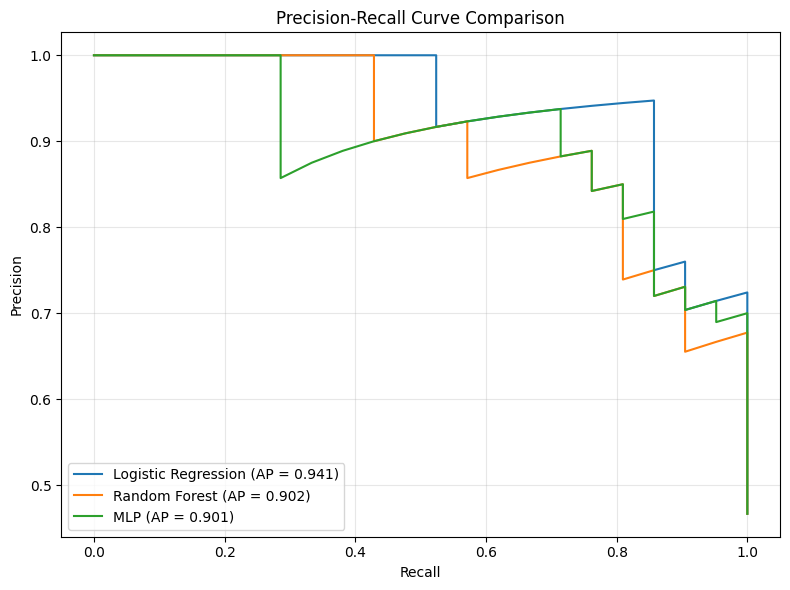

In [111]:
curves = {
    "Logistic Regression": logreg_curve,
    "Random Forest": rf_curve,
    "MLP": mlp_curve
}

plot_precision_recall_comparison(curves)